# Gaussian EM validation for transformer imputation

**S6-A02 · Sprint 6 · Subteam A · Rishank Goyal**

This parent ticket consolidates Gaussian EM’s field recovery, gas-feature ablation, and performance under heavier or grouped gaps. Its relative strengths depend on feature configuration and on whether the evaluation prioritises mean skill or field-level tolerances.

**Run this notebook.** Use a Python 3 Jupyter kernel with pandas and Matplotlib, then run all cells. The tables and figures use embedded extracts of the saved benchmark scores. They reproduce the analysis from those scores.

## Validation scope

Gaussian EM fits a shared-covariance Gaussian mixture on incomplete training rows. It uses the observed entries to estimate missing values from conditional component distributions. The review uses saved held-out scores from Subteam C’s synthetic transformer benchmark.

The scattered anchor and grouped scenario use nine matched generator–split pairs. The 70% missingness scenario uses three pairs from seed 219. Mean skill weights the 13 numeric targets equally within each pair. The field counts pool errors and tolerance hits by target before applying the break rule.

In [1]:
%matplotlib inline
from io import StringIO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PAIR = ["generator_seed", "split_seed"]
FIELD = {
    "x": "x", "y": "y", "install_date": "Installation day", "model_id": "Model ID",
    "altitude": "Altitude", "measured_humid": "Humidity", "measured_salt": "Salt",
    "measured_overgrowth": "Overgrowth", "life": "Life", "random_placebo": "Placebo",
    "measured_gas_a": "Gas A", "measured_gas_b": "Gas B", "measured_gas_c": "Gas C",
    "total_gas": "Total gas", "leakage": "Leakage",
}
TEAL, NAVY, RUST, MUTE = "#087973", "#203e53", "#a3452a", "#647783"
plt.rcParams.update({
    "figure.dpi": 140, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY, "axes.axisbelow": True, "grid.alpha": 0.22,
})

In [2]:
CONDITIONS = ["30% scattered", "70% scattered", "30% grouped"]
NAMES = {"mixture": "Gaussian EM", "forest": "MissForest"}

In [3]:
# Archived score extract. Rows and columns are restricted to this analysis.
anchor_targets = pd.read_csv(StringIO("""
method,attribute,skill
forest,altitude,0.6077047939800517
forest,install_date,0.8886642446447497
forest,life,0.6712247171460145
forest,measured_gas_c,0.8139282779847041
forest,x,0.8859360241077986
forest,y,0.5017176264793377
mixture,altitude,0.7494769095160591
mixture,install_date,0.9181559540023778
mixture,life,0.4987947991483159
mixture,measured_gas_c,0.6438926737105855
mixture,x,0.9173050156786703
mixture,y,0.6631400376989176
"""))

In [4]:
# Archived score extract. Rows and columns are restricted to this analysis.
feature_evidence = pd.read_csv(StringIO("""
method,domain_features,generator_seed,split_seed,macro_skill
forest,False,219,617,0.6642341630541152
forest,False,219,631,0.6608413113918605
forest,False,219,653,0.6762915704986026
forest,False,220,617,0.648656961862767
forest,False,220,631,0.6492004161908569
forest,False,220,653,0.6442835041295262
forest,False,221,617,0.663351161771389
forest,False,221,631,0.657066562078171
forest,False,221,653,0.6468787822696609
mixture,False,219,617,0.6649825131105891
mixture,False,219,631,0.6703647833723299
mixture,False,219,653,0.6825830492599703
mixture,False,220,617,0.6745476133101309
mixture,False,220,631,0.658769395864953
mixture,False,220,653,0.6697157016132493
mixture,False,221,617,0.6770019062579938
mixture,False,221,631,0.6705748097830926
mixture,False,221,653,0.6742750268397197
forest,True,219,617,0.6596825490762511
forest,True,219,631,0.6571734366552107
forest,True,219,653,0.6757834428651043
forest,True,220,617,0.6447390835743599
forest,True,220,631,0.6479006784508734
forest,True,220,653,0.6469302627325839
forest,True,221,617,0.6634616074595393
forest,True,221,631,0.654266810658674
forest,True,221,653,0.6521064775801411
mixture,True,219,617,0.644998559884692
mixture,True,219,631,0.6382115841116982
mixture,True,219,653,0.6510077669600933
mixture,True,220,617,0.6445509206530768
mixture,True,220,631,0.6225757104277669
mixture,True,220,653,0.6403510784764035
mixture,True,221,617,0.6463650339577007
mixture,True,221,631,0.6394036191175773
mixture,True,221,653,0.641803448753457
"""))

In [5]:
# Archived score extract. Rows and columns are restricted to this analysis.
pair_scores = pd.read_csv(StringIO("""
condition,generator_seed,split_seed,skill
30% grouped,219,617,0.4421649518655134
30% grouped,219,631,0.445052490817387
30% grouped,219,653,0.4340283618025543
30% grouped,220,617,0.4497096393372436
30% grouped,220,631,0.4212460776926052
30% grouped,220,653,0.4339582423864921
30% grouped,221,617,0.433091147092231
30% grouped,221,631,0.4281078797774451
30% grouped,221,653,0.4271193898476855
30% scattered,219,617,0.644998559884692
30% scattered,219,631,0.6382115841116982
30% scattered,219,653,0.6510077669600933
30% scattered,220,617,0.6445509206530768
30% scattered,220,631,0.6225757104277669
30% scattered,220,653,0.6403510784764035
30% scattered,221,617,0.6463650339577007
30% scattered,221,631,0.6394036191175773
30% scattered,221,653,0.641803448753457
70% scattered,219,617,0.3378038634502779
70% scattered,219,631,0.3556106389953966
70% scattered,219,653,0.3420017068541999
"""))

In [6]:
# Archived score extract. Rows and columns are restricted to this analysis.
field_totals = pd.read_csv(StringIO("""
condition,attribute,n,absolute_error,floor_absolute_error,within_n
30% grouped,altitude,5290,129814.8989910521,173462,502
30% grouped,install_date,5403,270493.5182493145,1852814,3926
30% grouped,leakage,5385,463.2940367594942,536.1723491720184,3317
30% grouped,life,5296,867004.4415590673,1513073.038285659,5053
30% grouped,measured_gas_a,5281,2891457.529435033,6561147.097304152,4372
30% grouped,measured_gas_b,5281,2111749.956285488,5645243.993918253,4649
30% grouped,measured_gas_c,5281,2808664.903223411,5070121.959095811,4543
30% grouped,measured_humid,5399,611.9827906305081,938.4355165999679,1565
30% grouped,measured_overgrowth,5399,979.7659305640275,1593.494755886614,1323
30% grouped,measured_salt,5399,1098.936906674858,1128.530418745932,878
30% grouped,total_gas,5281,1703228.024236235,5599666.657255469,5153
30% grouped,x,5290,20418.49078825236,131345,4372
30% grouped,y,5290,127780.287427838,135631,507
30% scattered,altitude,5458,45047.5137321877,179380,3773
30% scattered,install_date,5403,151540.2243989942,1852814,4171
30% scattered,leakage,5385,461.0757063971874,536.1723491720184,3358
30% scattered,life,5296,757253.8493229212,1513073.038285659,5174
30% scattered,measured_gas_a,5281,1661791.399569153,6561147.097304152,5018
30% scattered,measured_gas_b,5454,1244606.405139173,5825926.362990587,5263
30% scattered,measured_gas_c,5444,1851788.696025034,5208151.908488499,5259
30% scattered,measured_humid,5399,417.0865279310569,938.4355165999679,2320
30% scattered,measured_overgrowth,5326,561.903348067077,1600.181509060026,2178
30% scattered,measured_salt,5360,775.0402879346062,1124.471506385375,1536
30% scattered,total_gas,5360,1420462.649403343,5817174.502253948,5355
30% scattered,x,5290,10856.64151342667,131345,4795
30% scattered,y,5415,46098.9335192312,136718,3765
70% scattered,altitude,4194,93484.96283513587,138618,564
70% scattered,install_date,4235,584287.2284907497,1474368,743
70% scattered,leakage,4163,411.8137496656234,419.6817296148529,2152
70% scattered,life,4196,891874.2924377673,1181909.730747394,3819
70% scattered,measured_gas_a,4239,2530089.094118741,5252465.325226177,3201
70% scattered,measured_gas_b,4198,2459610.758541418,4432906.109779611,3230
70% scattered,measured_gas_c,4253,2350341.322851922,4119818.807712564,3428
70% scattered,measured_humid,4207,541.7640878864357,722.6247782290255,1040
70% scattered,measured_overgrowth,4196,907.5609366923425,1260.685921254642,594
70% scattered,measured_salt,4185,842.9521303270885,886.6480489046298,692
70% scattered,total_gas,4132,2031437.800060968,4516328.796437219,3916
70% scattered,x,4241,42278.53314572181,106912,1558
70% scattered,y,4165,88786.35880723903,106512,573
"""))

## Field recovery and feature comparison

In [7]:
paired = feature_evidence.pivot(index=["method", *PAIR], columns="domain_features", values="macro_skill")
paired = paired.rename(columns={False: "Without correction", True: "With correction"})
paired["Change"] = paired["With correction"] - paired["Without correction"]
assert paired.groupby(level="method").size().eq(9).all()
means = paired.groupby(level="method").mean()
em = means.loc["mixture"].round(3)
assert tuple(em) == (0.671, 0.641, -0.030)

In [8]:
selected = anchor_targets.pivot(index="attribute", columns="method", values="skill")
selected = selected.rename(index=FIELD, columns=NAMES).loc[
    ["x", "y", "Installation day", "Altitude", "Life", "Gas C"]
]
display(selected.style.format(precision=3))
display(means.rename(index=NAMES).style.format(precision=3))

method,MissForest,Gaussian EM
attribute,,
x,0.886,0.917
y,0.502,0.663
Installation day,0.889,0.918
Altitude,0.608,0.749
Life,0.671,0.499
Gas C,0.814,0.644


domain_features,Without correction,With correction,Change
method,,,
MissForest,0.657,0.656,-0.001
Gaussian EM,0.671,0.641,-0.030


## Performance under heavy and grouped gaps

In [9]:
field_totals["Skill"] = 1 - field_totals.absolute_error / field_totals.floor_absolute_error
field_totals["Within loose"] = field_totals.within_n / field_totals.n
field_totals["Fields that break"] = field_totals.Skill.lt(0.10) | field_totals["Within loose"].lt(0.50)
field_totals["Fields below floor"] = field_totals.Skill.lt(0)
performance = pair_scores.groupby("condition").skill.agg(["size", "mean"]).rename(columns={
    "size": "Pairs", "mean": "Mean numeric skill",
})
breaks = field_totals.groupby("condition")[["Fields that break", "Fields below floor"]].sum()
overview = performance.join(breaks).loc[CONDITIONS]
assert overview.Pairs.tolist() == [9, 3, 9]
assert overview["Mean numeric skill"].round(3).tolist() == [0.641, 0.345, 0.435]
assert overview["Fields that break"].tolist() == [3, 8, 5]
assert overview["Fields below floor"].tolist() == [0, 0, 0]
display(overview.style.format({"Mean numeric skill": "{:.3f}"}))
grouped_breaks = field_totals.loc[field_totals.condition.eq("30% grouped") & field_totals["Fields that break"]]
display(grouped_breaks.assign(Field=grouped_breaks.attribute.map(FIELD)).set_index("Field")[
    ["Skill", "Within loose"]
].style.format({"Skill": "{:.3f}", "Within loose": "{:.1%}"}))

,Pairs,Mean numeric skill,Fields that break,Fields below floor
condition,,,,
30% scattered,9,0.641,3,0
70% scattered,3,0.345,8,0
30% grouped,9,0.435,5,0


,Skill,Within loose
Field,,
Altitude,0.252,9.5%
Humidity,0.348,29.0%
Overgrowth,0.385,24.5%
Salt,0.026,16.3%
y,0.058,9.6%


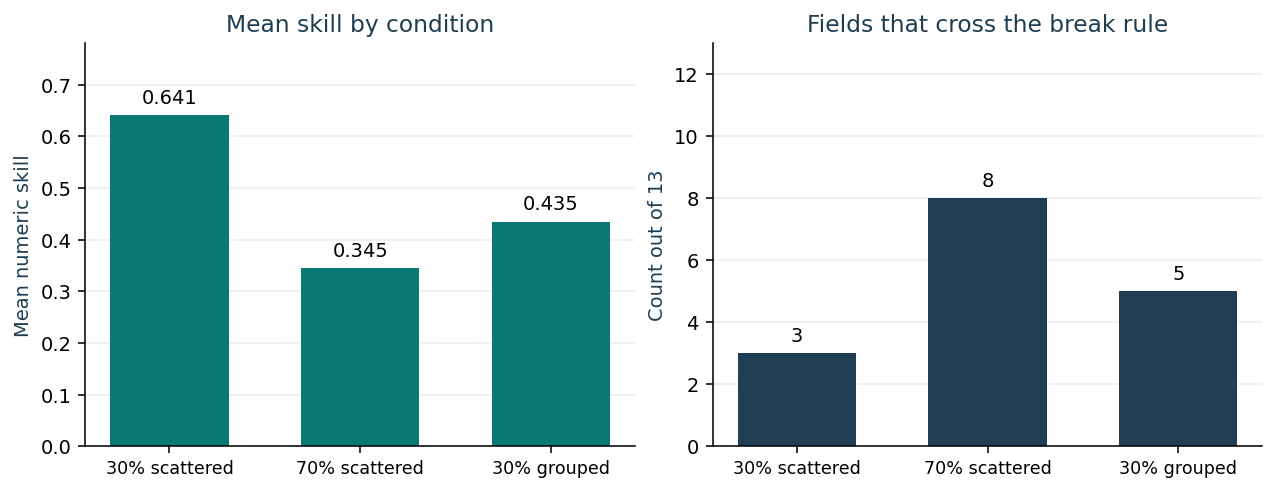

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.4), layout="constrained")
score = axes[0].bar(overview.index, overview["Mean numeric skill"], color=TEAL, width=0.62)
axes[0].bar_label(score, fmt="%.3f", padding=4)
axes[0].set(title="Mean skill by condition", ylabel="Mean numeric skill", ylim=(0, 0.78))
count = axes[1].bar(overview.index, overview["Fields that break"], color=NAVY, width=0.62)
axes[1].bar_label(count, fmt="%d", padding=4)
axes[1].set(title="Fields that cross the break rule", ylabel="Count out of 13", ylim=(0, 13))
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y")
plt.show()

## Ticket conclusions

- **A02.1** Gaussian EM leads MissForest on location and installation day at the feature-enabled anchor. MissForest has higher mean skill, while Gaussian EM has fewer field breaks.
- **A02.2** Decay correction lowers Gaussian EM’s mean anchor skill by about 0.030 and reverses its ranking relative to MissForest. The cause of the loss remains unresolved.
- **A02.3** Gaussian EM stays at or above the median floor on every numeric field under grouped gaps, while five fields still break. The grouped-trained MLP has higher mean grouped skill in the shared benchmark.

## Subticket attachments

- [A02.1 Anchor field recovery](A02_1_Gaussian_EM_Anchor.ipynb)
- [A02.2 Gas feature ablation](A02_2_Gaussian_EM_Gas_Feature_Ablation.ipynb)
- [A02.3 Heavy and grouped gaps](A02_3_Gaussian_EM_Stress_Tests.ipynb)

## Sources and reproducibility

Paths are relative to the original Subteam A run archive. Hash prefixes identify the archived files. The embedded extracts allow the calculations above to run in a fresh notebook session. Use the repository’s setup and benchmark instructions to reproduce the source runs with the Team 19 data.

| Archived source | Evidence used | SHA-256 prefix |
| --- | --- | --- |
| final/tables/cells.csv | Anchor field skills, independent heavy-gap scores and derived field totals | 9d8119486d0cbae0 |
| final/tables/macro_run_scores.csv | Paired anchor feature-ablation results | 280b4303444c8d02 |
| anchor-stress/tables/cells.csv | Grouped field scores and derived field totals | f4b3c14586d8bf47 |

[Sections 6, 7, 8A, and 10 of the capstone report](https://github.com/alienblack/SAPN_endtoend/blob/6ae6621/docs/Final_Report.pdf) · [Source code and reproduction guide](https://github.com/alienblack/SAPN_endtoend)